In [1]:
%pip install joblib matplotlib numpy pandas scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import json, platform, sys, time, warnings
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy, sklearn
from scipy.stats import wilcoxon
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import (ExtraTreesRegressor, HistGradientBoostingRegressor,
                              RandomForestRegressor, VotingRegressor)
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

try:
    from IPython.display import display
except ImportError:  # por si se ejecuta fuera de Jupyter
    display = print

warnings.filterwarnings("ignore")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
COLOR, ALERT = "#2f6f8f", "#b04a3a"

sys.path.insert(0, "../backend")                       # aquí vive ml_core.py (código compartido con el servicio)
DATA_PATH = Path("../data/movies.csv")
MODELS_DIR = Path("../backend/models"); MODELS_DIR.mkdir(exist_ok=True)   # artefactos que carga el servicio
SEED = 42
TARGET = "score"
TRAIN_END_YEAR = 2016          # train: <= 2016  |  test ciego: 2017-2020
N_ITER = 12                    # combinaciones por modelo en el tuning (baja a 4 para probar rápido)

# Criterios de aceptación definidos en la fase 1
ACCEPT_MAE, ACCEPT_MIN_IMPROVEMENT, ACCEPT_MIN_R2, LEAKAGE_R2_ALERT = 0.65, 0.10, 0.30, 0.80

In [3]:
raw = pd.read_csv(DATA_PATH)
print(f"{raw.shape[0]} filas × {raw.shape[1]} columnas | años {raw['year'].min()}–{raw['year'].max()} | duplicados: {raw.duplicated().sum()}")
nulls = pd.DataFrame({"nulos": raw.isna().sum(), "%": (raw.isna().mean() * 100).round(2)}).sort_values("nulos", ascending=False)
display(nulls[nulls["nulos"] > 0])

7668 filas × 15 columnas | años 1980–2020 | duplicados: 0


,nulos,%
budget,2171,28.31
gross,189,2.46
rating,77,1.00
company,17,0.22
runtime,4,0.05
score,3,0.04
votes,3,0.04
country,3,0.04
writer,3,0.04
released,2,0.03


score: media 6.390 | desv. est. 0.969 | MAE de predecir la media: 0.756


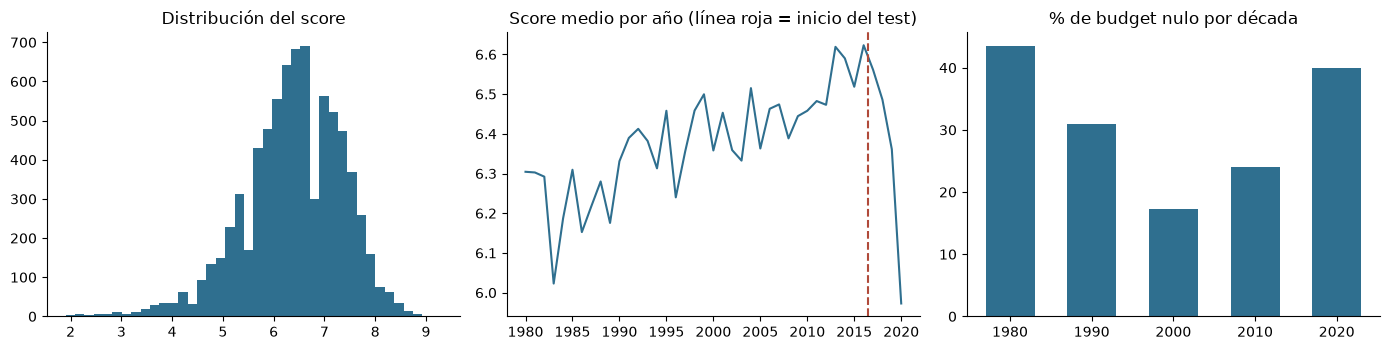

In [4]:
s = raw[TARGET].dropna()
print(f"score: media {s.mean():.3f} | desv. est. {s.std():.3f} | MAE de predecir la media: {(s - s.mean()).abs().mean():.3f}")
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].hist(s, bins=40, color=COLOR); ax[0].set_title("Distribución del score")
ym = raw.groupby("year")[TARGET].mean()
ax[1].plot(ym.index, ym.values, color=COLOR); ax[1].axvline(TRAIN_END_YEAR + .5, color=ALERT, ls="--"); ax[1].set_title("Score medio por año (línea roja = inicio del test)")
dec = raw.groupby(raw["year"] // 10 * 10)["budget"].apply(lambda x: x.isna().mean() * 100)
ax[2].bar(dec.index.astype(str), dec.values, color=COLOR, width=.6); ax[2].set_title("% de budget nulo por década")
plt.tight_layout(); plt.show()

In [5]:
# Cardinalidad: por qué one-hot no sirve para director / writer / star / company
rows = []
for c in ["director", "writer", "star", "company", "country", "genre", "rating"]:
    vc = raw[c].value_counts()
    rows.append({"columna": c, "únicos": raw[c].nunique(), "aparecen 1 sola vez": int((vc == 1).sum()), "más frecuente": vc.index[0]})
display(pd.DataFrame(rows))
print("Valor basura en director ('Directors'):", (raw["director"] == "Directors").sum(), "filas")

,columna,únicos,aparecen 1 sola vez,más frecuente
0,director,2949,1558,Woody Allen
1,writer,4535,3127,Woody Allen
2,star,2814,1771,Nicolas Cage
3,company,2385,1695,Universal Pictures
4,country,59,11,United States
5,genre,19,3,Comedy
6,rating,12,2,R


Valor basura en director ('Directors'): 28 filas


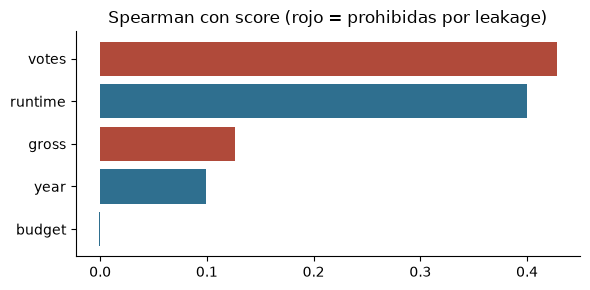

,score,votes,gross,budget,runtime,year
score,1.00,0.43,0.13,-0.00,0.40,0.10
votes,0.43,1.00,0.74,0.50,0.29,0.47
gross,0.13,0.74,1.00,0.69,0.25,0.29
budget,-0.00,0.50,0.69,1.00,0.34,0.32
runtime,0.40,0.29,0.25,0.34,1.00,0.14
year,0.10,0.47,0.29,0.32,0.14,1.00


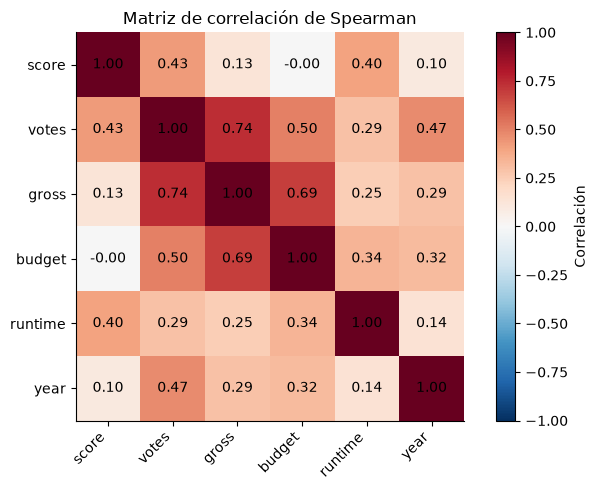

In [6]:
# Correlaciones con el score: votes y gross se ven "buenas", pero solo existen tras el estreno
numeric_cols = ["score", "votes", "gross", "budget", "runtime", "year"]
corr_matrix = raw[numeric_cols].corr(method="spearman")
cor = corr_matrix["score"].drop("score").sort_values()
fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(cor.index, cor.values, color=[ALERT if i in ("votes", "gross") else COLOR for i in cor.index])
ax.set_title("Spearman con score (rojo = prohibidas por leakage)"); plt.tight_layout(); plt.show()

# Matriz de correlación de las variables numéricas
display(corr_matrix.round(2))
fig, ax = plt.subplots(figsize=(7, 5))
image = ax.imshow(corr_matrix, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(numeric_cols)), labels=numeric_cols, rotation=45, ha="right")
ax.set_yticks(range(len(numeric_cols)), labels=numeric_cols)
for i in range(len(numeric_cols)):
    for j in range(len(numeric_cols)):
        ax.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}", ha="center", va="center", color="black")
ax.set_title("Matriz de correlación de Spearman")
fig.colorbar(image, ax=ax, label="Correlación")
plt.tight_layout(); plt.show()

In [7]:
from ml_core import (CAT_COLS, ENTITY_COLS, FORBIDDEN_COLS, INPUT_COLS, GenreYearBudgetImputer,
                     HistoryEncoder, build_pipeline, build_preprocessor, make_ensemble as _make_ensemble,
                     make_model, prepare_features, regression_metrics)

# Dataset limpio: se eliminan las filas sin score (3)
df = raw[raw[TARGET].notna()].reset_index(drop=True)
X, y = prepare_features(df), df[TARGET].astype(float)
assert not set(FORBIDDEN_COLS) & set(X.columns), "¡Variable prohibida en las entradas!"

# Split temporal ANTES de imputar o codificar nada
is_train = X["year"] <= TRAIN_END_YEAR
Xtr, ytr = X[is_train].reset_index(drop=True), y[is_train].reset_index(drop=True)
Xte, yte = X[~is_train].reset_index(drop=True), y[~is_train].reset_index(drop=True)

# CV temporal (forward-chaining): entrena con años < bloque, valida en el bloque
CV_VAL_BLOCKS = [(1997, 2000), (2001, 2004), (2005, 2008), (2009, 2012), (2013, 2016)]
def temporal_folds(years, blocks=CV_VAL_BLOCKS):
    years = np.asarray(years)
    return [(np.where(years < lo)[0], np.where((years >= lo) & (years <= hi))[0]) for lo, hi in blocks]
folds = temporal_folds(Xtr["year"])

print(f"Train (≤{TRAIN_END_YEAR}): {len(Xtr)} | Test ciego: {len(Xte)} (no se toca hasta la sección 7)")
for i, (a, b) in enumerate(folds, 1):
    print(f"  fold {i}: entrena {len(a)} → valida {len(b)}")
print("Entradas del modelo:", INPUT_COLS)

Train (≤2016): 7043 | Test ciego: 622 (no se toca hasta la sección 7)
  fold 1: entrena 3043 → valida 800
  fold 2: entrena 3843 → valida 800
  fold 3: entrena 4643 → valida 800
  fold 4: entrena 5443 → valida 800
  fold 5: entrena 6243 → valida 800
Entradas del modelo: ['director', 'writer', 'star', 'company', 'genre', 'rating', 'country', 'release_month', 'year', 'runtime', 'log_budget', 'budget_missing']


In [8]:
rng = np.random.default_rng(SEED)
known = Xtr.index[Xtr["log_budget"].notna()]
mask = rng.choice(known, size=int(.25 * len(known)), replace=False)
Xm = Xtr.copy(); truth = Xm.loc[mask, "log_budget"].to_numpy(); Xm.loc[mask, "log_budget"] = np.nan

pred = {}
pred["Mediana global"] = SimpleImputer(strategy="median").fit(Xm[["log_budget"]]).transform(Xm[["log_budget"]])[:, 0]
pred["Mediana por género y año"] = GenreYearBudgetImputer().fit(Xm).transform(Xm)["log_budget"].to_numpy()
num = Xm[["year", "runtime", "log_budget"]]; sc = StandardScaler().fit(num)
knn = KNNImputer(n_neighbors=10).fit(sc.transform(num))
pred["KNN (k=10)"] = sc.inverse_transform(knn.transform(sc.transform(num)))[:, 2]
num2 = pd.concat([num, pd.get_dummies(Xm[["genre", "country"]].fillna("na"), dtype=float)], axis=1)
pred["Iterative (+género, país)"] = IterativeImputer(max_iter=10, random_state=SEED).fit(num2).transform(num2)[:, 2]

rows = [{"método": k, "RMSE log_budget": np.sqrt(np.mean((v[mask] - truth) ** 2)),
         "MAE log_budget": np.mean(np.abs(v[mask] - truth))} for k, v in pred.items()]
imp_tbl = pd.DataFrame(rows).sort_values("RMSE log_budget")
display(imp_tbl.round(3))

,método,RMSE log_budget,MAE log_budget
3,"Iterative (+género, país)",1.098,0.781
1,Mediana por género y año,1.193,0.809
2,KNN (k=10),1.262,0.913
0,Mediana global,1.367,0.976


In [9]:
# Los pipelines viven en backend/ml_core.py; aquí se muestra cómo se construye el preprocesamiento:
import inspect
print(inspect.getsource(build_preprocessor))


def cv_evaluate(factory, X, y, folds):
    rows = []
    for k, (tr, va) in enumerate(folds, 1):
        p = factory().fit(X.iloc[tr], y.iloc[tr])
        rows.append({**regression_metrics(y.iloc[va], p.predict(X.iloc[va])), "fold": k})
    return pd.DataFrame(rows)

# Prueba rápida: el pipeline completo no deja nulos y soporta un director inexistente
p0 = build_pipeline("hist_gb").fit(Xtr, ytr)
Z = p0.named_steps["prep"].transform(Xtr)
print("Features finales:", Z.shape[1], "| nulos restantes:", int(np.isnan(Z).sum()))
nuevo = Xte.iloc[:1].copy(); nuevo["director"] = "Director Inexistente"; nuevo["star"] = np.nan
print("Predicción con director inexistente y star nulo:", round(float(p0.predict(nuevo)[0]), 2), "(usa la media global, sin error)")

def build_preprocessor(imputer="genre_year", scale=False):
    """imputer: median | genre_year | knn | iterative | native (deja NaN; solo para HistGradientBoosting)."""
    num_cols = ["year", "runtime", "log_budget", "budget_missing"]
    if imputer in ("median", "genre_year"):
        steps = [("imp", SimpleImputer(strategy="median"))]
    elif imputer == "knn":
        steps = [("sc0", StandardScaler()), ("imp", KNNImputer(n_neighbors=10))]
    elif imputer == "iterative":
        steps = [("imp", IterativeImputer(max_iter=10, random_state=SEED))]
    elif imputer == "native":
        steps = []
    else:
        raise ValueError(imputer)
    if scale and imputer != "native":
        steps.append(("sc", StandardScaler()))
    num_branch = Pipeline(steps) if steps else "passthrough"
    cat_branch = Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="desconocido")),
                           ("ohe", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30,
 

In [10]:
rows = []
for imp in ["median", "genre_year", "knn", "iterative", "native"]:
    r = cv_evaluate(lambda imp=imp: build_pipeline("hist_gb", imputer=imp), Xtr, ytr, folds)
    rows.append({"imputación": imp, "MAE": r.mae.mean(), "MAE std folds": r.mae.std(), "R²": r.r2.mean()})
imp_eff = pd.DataFrame(rows).sort_values("MAE")
display(imp_eff.round(4))
spread, fold_std = imp_eff["MAE"].max() - imp_eff["MAE"].min(), imp_eff["MAE std folds"].mean()
print(f"Diferencia máxima entre métodos: {spread:.4f} | desviación media entre folds: {fold_std:.4f}")
print("→ Diferencias menores que el ruido entre folds. Se adopta 'genre_year': simple, determinista, explicable y fácil de reproducir en una API.")
IMP = "genre_year"

,imputación,MAE,MAE std folds,R²
3,iterative,0.5876,0.0457,0.3599
4,native,0.5876,0.0436,0.3593
1,genre_year,0.5881,0.0436,0.3565
2,knn,0.5890,0.0444,0.3551
0,median,0.5902,0.0479,0.3529


Diferencia máxima entre métodos: 0.0026 | desviación media entre folds: 0.0450
→ Diferencias menores que el ruido entre folds. Se adopta 'genre_year': simple, determinista, explicable y fácil de reproducir en una API.


,modelo,MAE,MAE std,RMSE,R²,seg,mejora vs baseline
0,random_forest,0.5833,0.0348,0.7628,0.3642,6.3,0.2341
1,extra_trees,0.5839,0.0376,0.7640,0.3632,5.5,0.2334
2,hist_gb,0.5881,0.0436,0.7671,0.3565,4.4,0.2279
3,ridge,0.6051,0.0372,0.7863,0.3239,2.5,0.2055
4,media (baseline),0.7617,0.0619,0.9697,-0.0259,2.6,0.0000


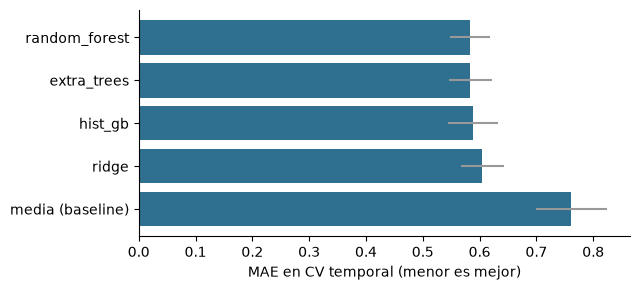

In [11]:
MODELS = ["media (baseline)", "ridge", "random_forest", "extra_trees", "hist_gb"]
rows = []
for name in MODELS:
    t = time.time()
    r = cv_evaluate(lambda n=name: build_pipeline(n, imputer=IMP), Xtr, ytr, folds)
    rows.append({"modelo": name, "MAE": r.mae.mean(), "MAE std": r.mae.std(), "RMSE": r.rmse.mean(), "R²": r.r2.mean(), "seg": round(time.time() - t, 1)})
comp = pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)
base_mae = comp.loc[comp["modelo"] == "media (baseline)", "MAE"].iloc[0]
comp["mejora vs baseline"] = (base_mae - comp["MAE"]) / base_mae
display(comp.round(4))

o = comp.sort_values("MAE", ascending=False)
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.barh(o["modelo"], o["MAE"], xerr=o["MAE std"], color=COLOR, ecolor="#999"); ax.set_xlabel("MAE en CV temporal (menor es mejor)")
plt.tight_layout(); plt.show()

In [12]:
# Análisis de errores del mejor modelo con predicciones fuera de muestra (OOF)
best_name = comp[comp["modelo"] != "media (baseline)"].iloc[0]["modelo"]
oof = pd.Series(np.nan, index=Xtr.index)
for tr, va in folds:
    oof.iloc[va] = build_pipeline(best_name, imputer=IMP).fit(Xtr.iloc[tr], ytr.iloc[tr]).predict(Xtr.iloc[va])
dtr = df[is_train].reset_index(drop=True)
d = dtr.assign(pred=oof).dropna(subset=["pred"])
d["err"] = (d["score"] - d["pred"]).abs(); d["resid"] = d["score"] - d["pred"]
g = d.groupby("genre").agg(n=("err", "size"), MAE=("err", "mean"), sesgo=("resid", "mean"))
display(g[g["n"] >= 100].sort_values("MAE", ascending=False).round(3))
print("Mayores errores (fracasos extremos que el modelo sobrestima):")
display(d.sort_values("err", ascending=False).head(6)[["name", "year", "genre", "score", "pred"]].round(2))

,n,MAE,sesgo
genre,,,
Animation,221,0.648,0.197
Horror,166,0.640,-0.207
Adventure,200,0.616,0.032
Comedy,1100,0.593,-0.022
Action,954,0.590,-0.020
Drama,783,0.574,0.067
Crime,293,0.513,0.082
Biography,243,0.501,0.255


Mayores errores (fracasos extremos que el modelo sobrestima):


,name,year,genre,score,pred
4022,Glitter,2001,Drama,2.3,6.48
4326,Gigli,2003,Comedy,2.5,6.63
4342,House of the Dead,2003,Action,2.1,6.19
5354,The Hottie & the Nottie,2008,Comedy,1.9,5.46
3684,Battlefield Earth,2000,Action,2.5,5.98
4594,Superbabies: Baby Geniuses 2,2004,Comedy,1.9,5.37


In [13]:
Xl = Xtr.copy()
raw_tr = df[is_train].reset_index(drop=True)
Xl["votes"], Xl["gross"] = np.log1p(raw_tr["votes"]), np.log1p(raw_tr["gross"])
rows = []
for label, cols in [("Variables permitidas (año, duración, presupuesto)", ["year", "runtime", "log_budget"]),
                    ("+ votes", ["year", "runtime", "log_budget", "votes"]),
                    ("+ votes + gross", ["year", "runtime", "log_budget", "votes", "gross"])]:
    m_, r_ = [], []
    for tr, va in folds:
        mdl = HistGradientBoostingRegressor(random_state=SEED, max_iter=200, learning_rate=.05).fit(Xl.iloc[tr][cols], ytr.iloc[tr])
        p = mdl.predict(Xl.iloc[va][cols]); m_.append(mean_absolute_error(ytr.iloc[va], p)); r_.append(r2_score(ytr.iloc[va], p))
    rows.append({"variables": label, "MAE": np.mean(m_), "R²": np.mean(r_)})
display(pd.DataFrame(rows).round(3))
print("votes sube el R² de forma artificial: en producción no existe cuando se quiere predecir. Si un R² parece demasiado bueno, hay leakage.")

,variables,MAE,R²
0,"Variables permitidas (año, duración, presupuesto)",0.661,0.185
1,+ votes,0.533,0.429
2,+ votes + gross,0.517,0.451


votes sube el R² de forma artificial: en producción no existe cuando se quiere predecir. Si un R² parece demasiado bueno, hay leakage.


In [14]:
SPACES = {
    "random_forest": {"model__n_estimators": [200, 400], "model__min_samples_leaf": [3, 5, 10, 20],
                      "model__max_features": [0.2, 0.33, 0.5, 0.8], "model__max_depth": [None, 12, 20]},
    "extra_trees": {"model__n_estimators": [200, 400], "model__min_samples_leaf": [3, 5, 10, 20],
                    "model__max_features": [0.2, 0.33, 0.5, 0.8], "model__max_depth": [None, 12, 20]},
    "hist_gb": {"model__learning_rate": [0.02, 0.03, 0.05, 0.08], "model__max_iter": [200, 400, 600],
                "model__max_leaf_nodes": [7, 15, 31], "model__min_samples_leaf": [20, 40, 80],
                "model__l2_regularization": [0.0, 1.0, 5.0, 10.0]},
}
tuned, cv_rows = {}, []
for name, space in SPACES.items():
    t = time.time()
    rs = RandomizedSearchCV(build_pipeline(name, imputer=IMP), space, n_iter=N_ITER, cv=folds,
                            scoring="neg_mean_absolute_error", random_state=SEED, refit=False, n_jobs=1).fit(Xtr, ytr)
    tuned[name] = {k.replace("model__", ""): v for k, v in rs.best_params_.items()}
    r = cv_evaluate(lambda n=name: build_pipeline(n, imputer=IMP, model=make_model(n).set_params(**tuned[n])), Xtr, ytr, folds)
    cv_rows.append({"modelo": f"{name} (tuneado)", "MAE": r.mae.mean(), "MAE std": r.mae.std(), "RMSE": r.rmse.mean(), "R²": r.r2.mean()})
    print(f"{name}: {tuned[name]}  → MAE CV {r.mae.mean():.4f}  ({time.time() - t:.0f}s)")

random_forest: {'n_estimators': 200, 'min_samples_leaf': 3, 'max_features': 0.2, 'max_depth': 20}  → MAE CV 0.5803  (63s)
extra_trees: {'n_estimators': 200, 'min_samples_leaf': 3, 'max_features': 0.5, 'max_depth': 20}  → MAE CV 0.5847  (59s)
hist_gb: {'min_samples_leaf': 20, 'max_leaf_nodes': 15, 'max_iter': 200, 'learning_rate': 0.03, 'l2_regularization': 0.0}  → MAE CV 0.5827  (63s)


In [15]:
def make_ensemble():
    return _make_ensemble(tuned, IMP)

r = cv_evaluate(make_ensemble, Xtr, ytr, folds)
cv_rows.append({"modelo": "ensamble (promedio RF+ET+HGB)", "MAE": r.mae.mean(), "MAE std": r.mae.std(), "RMSE": r.rmse.mean(), "R²": r.r2.mean()})
rb = cv_evaluate(lambda: build_pipeline("media (baseline)"), Xtr, ytr, folds)
cv_rows.append({"modelo": "media (baseline)", "MAE": rb.mae.mean(), "MAE std": rb.mae.std(), "RMSE": rb.rmse.mean(), "R²": rb.r2.mean()})
cv = pd.DataFrame(cv_rows).sort_values("MAE").reset_index(drop=True)
cv["mejora vs baseline"] = (rb.mae.mean() - cv["MAE"]) / rb.mae.mean()
display(cv.round(4))

# Regla de selección (solo CV): el ensamble gana únicamente si mejora ≥ 0,003 de MAE al mejor modelo simple
best_single = cv[cv["modelo"].str.contains("tuneado")].iloc[0]
ens_row = cv[cv["modelo"].str.startswith("ensamble")].iloc[0]
use_ens = (best_single["MAE"] - ens_row["MAE"]) >= 0.003
chosen_name = ens_row["modelo"] if use_ens else best_single["modelo"]
chosen_key = None if use_ens else best_single["modelo"].replace(" (tuneado)", "")

def make_final():
    return make_ensemble() if use_ens else build_pipeline(chosen_key, imputer=IMP, model=make_model(chosen_key).set_params(**tuned[chosen_key]))
chosen_cv = cv[cv["modelo"] == chosen_name].iloc[0]
print("MODELO ELEGIDO (solo con CV):", chosen_name)

,modelo,MAE,MAE std,RMSE,R²,mejora vs baseline
0,ensamble (promedio RF+ET+HGB),0.5753,0.0373,0.7527,0.3817,0.2446
1,random_forest (tuneado),0.5803,0.0389,0.7576,0.3739,0.2381
2,hist_gb (tuneado),0.5827,0.0394,0.7606,0.3681,0.2350
3,extra_trees (tuneado),0.5847,0.0366,0.7657,0.3602,0.2323
4,media (baseline),0.7617,0.0619,0.9697,-0.0259,0.0000


MODELO ELEGIDO (solo con CV): ensamble (promedio RF+ET+HGB)


In [16]:
final = make_final().fit(Xtr, ytr)
base = build_pipeline("media (baseline)").fit(Xtr, ytr)
p, pb = final.predict(Xte), base.predict(Xte)
m, mb = regression_metrics(yte, p), regression_metrics(yte, pb)

rng = np.random.default_rng(SEED)
e_m, e_b = np.abs(yte.values - p), np.abs(yte.values - pb)
idx = rng.integers(0, len(yte), (2000, len(yte)))
mae_ci = np.percentile(e_m[idx].mean(1), [2.5, 97.5])
imp_ci = np.percentile((e_b[idx].mean(1) - e_m[idx].mean(1)) / e_b[idx].mean(1), [2.5, 97.5])
wil = wilcoxon(e_b, e_m, alternative="greater")
improv = (mb["mae"] - m["mae"]) / mb["mae"]

display(pd.DataFrame({"modelo": [chosen_name, "baseline (media del train)"], "MAE": [m["mae"], mb["mae"]],
                      "RMSE": [m["rmse"], mb["rmse"]], "R²": [m["r2"], mb["r2"]]}).round(4))
print(f"Mejora de MAE vs baseline: {improv*100:.1f}%  (IC95% {imp_ci[0]*100:.1f}% a {imp_ci[1]*100:.1f}%)")
print(f"IC95% del MAE del modelo: [{mae_ci[0]:.3f}, {mae_ci[1]:.3f}]  |  Wilcoxon pareado p = {wil.pvalue:.2e}")

accept = {
    f"MAE ≤ {ACCEPT_MAE}": m["mae"] <= ACCEPT_MAE,
    f"Mejora ≥ {ACCEPT_MIN_IMPROVEMENT:.0%} vs baseline": improv >= ACCEPT_MIN_IMPROVEMENT,
    f"R² ≥ {ACCEPT_MIN_R2}": m["r2"] >= ACCEPT_MIN_R2,
    f"R² ≤ {LEAKAGE_R2_ALERT} (sin sospecha de leakage)": m["r2"] <= LEAKAGE_R2_ALERT,
    "CV estable (std MAE entre folds < 0,06)": chosen_cv["MAE std"] < 0.06,
}
print("\nCriterios de aceptación:")
for k, ok in accept.items():
    print(("  ✅ " if ok else "  ❌ ") + k)
print("→", "MODELO ACEPTADO" if all(accept.values()) else "El modelo NO cumple todos los criterios (ver ❌): decisión de negocio documentada en la Model Card.")

,modelo,MAE,RMSE,R²
0,ensamble (promedio RF+ET+HGB),0.6184,0.8492,0.1884
1,baseline (media del train),0.7317,0.9450,-0.0050


Mejora de MAE vs baseline: 15.5%  (IC95% 11.2% a 19.9%)
IC95% del MAE del modelo: [0.573, 0.662]  |  Wilcoxon pareado p = 3.79e-09

Criterios de aceptación:
  ✅ MAE ≤ 0.65
  ✅ Mejora ≥ 10% vs baseline
  ❌ R² ≥ 0.3
  ✅ R² ≤ 0.8 (sin sospecha de leakage)
  ✅ CV estable (std MAE entre folds < 0,06)
→ El modelo NO cumple todos los criterios (ver ❌): decisión de negocio documentada en la Model Card.


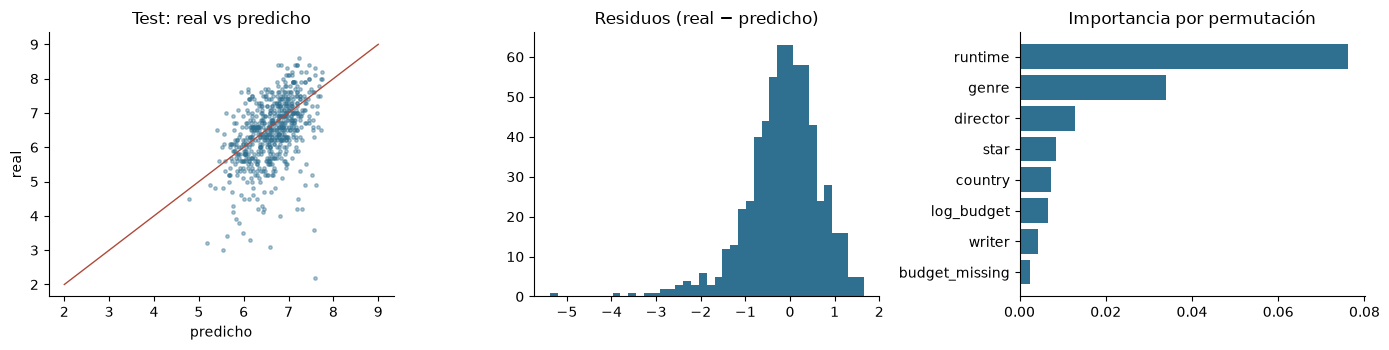

In [17]:
# Resultados gráficos + importancia por permutación (descriptiva, sobre las columnas de entrada)
imp_rows = []
for c in INPUT_COLS:
    dlt = []
    for k in range(5):
        Xp = Xte.copy(); Xp[c] = Xp[c].sample(frac=1, random_state=SEED + k).values
        dlt.append(mean_absolute_error(yte, final.predict(Xp)) - m["mae"])
    imp_rows.append({"variable": c, "aumento de MAE al permutar": np.mean(dlt)})
imp = pd.DataFrame(imp_rows).sort_values("aumento de MAE al permutar", ascending=False)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].scatter(p, yte, s=6, alpha=.4, color=COLOR); ax[0].plot([2, 9], [2, 9], color=ALERT, lw=1)
ax[0].set_xlabel("predicho"); ax[0].set_ylabel("real"); ax[0].set_title("Test: real vs predicho")
ax[1].hist(yte.values - p, bins=40, color=COLOR); ax[1].set_title("Residuos (real − predicho)")
t_ = imp.head(8).iloc[::-1]; ax[2].barh(t_["variable"], t_["aumento de MAE al permutar"], color=COLOR); ax[2].set_title("Importancia por permutación")
plt.tight_layout(); plt.show()

In [18]:
# Error por subgrupo: ¿es menos fiable con directores sin historial?
seen = set(Xtr["director"].dropna())
sub = pd.DataFrame({"err": e_m,
                    "director": np.where(Xte["director"].isin(seen), "con historial", "nuevo"),
                    "país": np.where(Xte["country"] == "United States", "EE.UU.", "otros")})
display(pd.concat([sub.groupby(c)["err"].agg(n="size", MAE="mean") for c in ["director", "país"]]).round(3))

# R² por año del test: el R² con ~200 películas por año es ruidoso
rows = []
for yr in sorted(Xte["year"].unique()):
    k = (Xte["year"] == yr).to_numpy()
    rows.append({"año": int(yr), "n": int(k.sum()), "MAE": mean_absolute_error(yte[k], p[k]),
                 "MAE baseline": np.abs(yte[k] - ytr.mean()).mean(), "R²": r2_score(yte[k], p[k])})
display(pd.DataFrame(rows).round(3))

,n,MAE
con historial,343,0.562
nuevo,279,0.688
EE.UU.,378,0.599
otros,244,0.648


,año,n,MAE,MAE baseline,R²
0,2017,200,0.596,0.704,0.228
1,2018,200,0.531,0.705,0.353
2,2019,200,0.702,0.769,0.029
3,2020,22,0.852,0.900,-0.032


In [19]:
def save_version(version, pipeline, algorithm, train_years, test_years,
                 n_train, n_test, cv_metrics, test_metrics, baseline_metrics,
                 improvement, accepted, extra=None, activate=True):
    joblib.dump(pipeline, MODELS_DIR / f"model_{version}.joblib", compress=3)

    meta = {
        "model_version": version,
        "trained_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "algorithm": algorithm,
        "hyperparameters": tuned,
        "imputation": IMP,
        "seed": SEED,
        "train_years": train_years,
        "test_years": test_years,
        "n_train": n_train,
        "n_test": n_test,
        "input_columns": INPUT_COLS,
        "excluded_columns": FORBIDDEN_COLS,
        "cv_metrics": cv_metrics,
        "test_metrics": test_metrics,
        "baseline_test_metrics": baseline_metrics,
        "improvement_vs_baseline": float(improvement),
        "accepted": bool(accepted),
        "versions": {
            "python": platform.python_version(),
            "sklearn": sklearn.__version__,
            "pandas": pd.__version__,
            "numpy": np.__version__,
        },
        **(extra or {}),
    }

    metadata_path = MODELS_DIR / f"model_{version}_metadata.json"
    metadata_path.write_text(
        json.dumps(meta, indent=2, ensure_ascii=False, default=float),
        encoding="utf-8",
    )

    reg_path = MODELS_DIR / "registry.json"
    reg = (
        json.loads(reg_path.read_text(encoding="utf-8"))
        if reg_path.exists()
        else {"active": None, "versions": []}
    )

    reg["versions"] = [v for v in reg["versions"] if v != version] + [version]
    if activate:
        reg["active"] = version

    reg_path.write_text(
        json.dumps(reg, indent=2, ensure_ascii=False),
        encoding="utf-8",
    )
    return meta


meta = save_version(
    "v1",
    final,
    chosen_name,
    [int(Xtr["year"].min()), TRAIN_END_YEAR],
    [TRAIN_END_YEAR + 1, int(Xte["year"].max())],
    len(Xtr),
    len(Xte),
    {
        "mae": chosen_cv["MAE"],
        "rmse": chosen_cv["RMSE"],
        "r2": chosen_cv["R²"],
    },
    m,
    mb,
    improv,
    all(accept.values()),
    extra={
        "test_mae_ci95": [float(mae_ci[0]), float(mae_ci[1])],
        "acceptance_checks": {k: bool(v) for k, v in accept.items()},
    },
)

print("Guardado:", sorted(f.name for f in MODELS_DIR.iterdir()))

Guardado: ['model_v1.joblib', 'model_v1_metadata.json', 'registry.json']


In [20]:
def load_active():
    reg = json.loads((MODELS_DIR / "registry.json").read_text())
    return reg["active"], joblib.load(MODELS_DIR / f"model_{reg['active']}.joblib")


def predict_movie(record: dict, pipeline=None, train_directors=None):
    """Predice el score de UNA película con variables de pre-producción.
    Cualquier campo extra (votes, gross, name...) se ignora; faltantes se imputan."""
    if pipeline is None:
        _, pipeline = load_active()
    row = pd.DataFrame([record])
    Xr = prepare_features(row)
    score = float(pipeline.predict(Xr)[0])
    known = bool(record.get("director") in set(train_directors if train_directors is not None else Xtr["director"].dropna()))
    return {"predicted_score": round(score, 2), "known_director": known, "budget_imputed": bool(Xr["budget_missing"].iloc[0])}

ver, active = load_active()
print("Versión activa:", ver)
print(predict_movie({"director": "Christopher Nolan", "genre": "Drama", "year": 2024, "runtime": 150, "budget": 100e6,
                     "release_month": "July", "country": "United States", "rating": "PG-13", "votes": 999999}))
print(predict_movie({"director": "Director Nuevo", "genre": "Comedy", "year": 2024}))

Versión activa: v1
{'predicted_score': 7.39, 'known_director': True, 'budget_imputed': False}
{'predicted_score': 7.05, 'known_director': False, 'budget_imputed': True}


In [21]:
def retrain(df_total, holdout_years=2, dry_run=True):
    d = df_total[df_total[TARGET].notna()].reset_index(drop=True)
    X_all, y_all = prepare_features(d), d[TARGET].astype(float)
    cut = int(X_all["year"].max()) - holdout_years
    tr = (X_all["year"] <= cut).to_numpy()
    Xa, ya, Xh, yh = X_all[tr].reset_index(drop=True), y_all[tr].reset_index(drop=True), X_all[~tr], y_all[~tr]

    active_ver, active_pipe = load_active()
    active_meta = json.loads((MODELS_DIR / f"model_{active_ver}_metadata.json").read_text())
    if active_meta["train_years"][1] >= int(Xh["year"].min()):
        print(f"⚠ El modelo activo ({active_ver}) ya vio años del holdout; la comparación no es justa. Usa más datos nuevos.")

    candidate = make_final().fit(Xa, ya)
    m_c = regression_metrics(yh, candidate.predict(Xh))
    m_a = regression_metrics(yh, active_pipe.predict(Xh))
    m_b = regression_metrics(yh, DummyRegressor().fit(Xa, ya).predict(Xh))
    promote = m_c["mae"] < m_a["mae"]

    new_ver = f"v{int(active_ver[1:]) + 1}"
    print(f"Holdout {int(Xh['year'].min())}–{int(Xh['year'].max())} (n={len(Xh)}) | entrenado hasta {cut} con {len(Xa)} filas")
    print(f"  activo {active_ver}: MAE {m_a['mae']:.4f} | candidato {new_ver}: MAE {m_c['mae']:.4f} | baseline: {m_b['mae']:.4f}")
    print("  →", f"PROMOVER {new_ver}" if promote else f"se conserva {active_ver}", "(dry_run: no se guardó nada)" if dry_run else "")
    if promote and not dry_run:
        save_version(new_ver, candidate, chosen_name, [int(Xa["year"].min()), cut], [int(Xh["year"].min()), int(Xh["year"].max())],
                     len(Xa), len(Xh), chosen_cv[["MAE", "RMSE", "R²"]].rename({"MAE": "mae", "RMSE": "rmse", "R²": "r2"}).to_dict(),
                     m_c, m_b, (m_b["mae"] - m_c["mae"]) / m_b["mae"], accepted=False,
                     extra={"retrain_from": active_ver, "holdout_active_metrics": m_a})
    return {"promoted": bool(promote), "candidate": m_c, "active": m_a, "baseline": m_b}

# Demo con los datos actuales (dry_run=True: no modifica el registro). Con datos nuevos: retrain(pd.concat([raw, nuevos]), dry_run=False)
_ = retrain(raw, holdout_years=2, dry_run=True)

Holdout 2019–2020 (n=222) | entrenado hasta 2018 con 7443 filas
  activo v1: MAE 0.7172 | candidato v2: MAE 0.7081 | baseline: 0.7814
  → PROMOVER v2 (dry_run: no se guardó nada)


In [22]:
print(f"Modelo: {chosen_name}")
print(f"CV temporal : MAE {chosen_cv['MAE']:.3f} | RMSE {chosen_cv['RMSE']:.3f} | R² {chosen_cv['R²']:.3f}")
print(f"Test ciego  : MAE {m['mae']:.3f} | RMSE {m['rmse']:.3f} | R² {m['r2']:.3f}   (baseline MAE {mb['mae']:.3f})")
print(f"Mejora vs baseline: {improv*100:.1f}%  |  aceptado: {all(accept.values())}")
print("Archivos que usa el servicio: backend/ml_core.py + backend/models/model_v1.joblib + model_v1_metadata.json")

Modelo: ensamble (promedio RF+ET+HGB)
CV temporal : MAE 0.575 | RMSE 0.753 | R² 0.382
Test ciego  : MAE 0.618 | RMSE 0.849 | R² 0.188   (baseline MAE 0.732)
Mejora vs baseline: 15.5%  |  aceptado: False
Archivos que usa el servicio: backend/ml_core.py + backend/models/model_v1.joblib + model_v1_metadata.json


**Siguiente paso (backend).** El servicio (`backend/`) carga `models/model_v1.joblib` junto con `ml_core.py` y registra los metadatos
(`model_v1_metadata.json`) en su base de datos. `registry.json`, `predict_movie` y `retrain` de este notebook son para pruebas locales;
el servicio tiene su propia versión del reentrenamiento que trabaja sobre la base de datos.